<a href="https://colab.research.google.com/github/HarshMittal03/data-analytics-projects/blob/main/capston_project_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Capstone Project 3**

# **Harsh Mittal (DATA ANALYST)**

# **Netfilx Exploratory Data Analysis (EDA)**

Import all the needed liberaries



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Data Exploration:

In [ ]:
df = pd.read_csv("/content/netflix_titles.csv")

In [ ]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.tail()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


Data Cleaning:



Check for missing values and handle them appropriately.

Remove duplicate entries if any.

Correct any inconsistencies or errors in the data.

In [ ]:
df = pd.read_csv("/content/netflix_titles.csv")
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


Director has 2634 null values we fill it ith unknown cast has 825 null vvalues we fill it with unknown country has 831 null values we fill it with unknown rating has 4 null values e fill it with mode of rating column

In [ ]:
data = df.copy()

num_cols = []
cat_cols = ["duration","rating","director","cast","country", "date_added"]

for col in num_cols:
    data[col] = data[col].fillna(data[col].median())

for col in cat_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

print("missing values:", data.isnull().sum().sum())

missing values: 0


In [ ]:
df.describe(include="object").transpose()

,count,unique,top,freq
show_id,8807,8807,s8807,1
type,8807,2,Movie,6131
title,8807,8807,Zubaan,1
director,6173,4528,Rajiv Chilaka,19
cast,7982,7692,David Attenborough,19
country,7976,748,United States,2818
date_added,8797,1767,"January 1, 2020",109
rating,8803,17,TV-MA,3207
duration,8804,220,1 Season,1793
listed_in,8807,514,"Dramas, International Movies",362


In [ ]:
data.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [ ]:
print(df.describe(include='all').T)
print('Mean release year:', df['release_year'].mean())
print('Median release year:', df['release_year'].median())
print('Mode content type:', df['type'].mode()[0])
print('Release-year range:', df['release_year'].max() - df['release_year'].min())
print('Standard deviation:', df['release_year'].std())

               count unique  \
show_id         8807   8807   
type            8807      2   
title           8807   8807   
director        6173   4528   
cast            7982   7692   
country         7976    748   
date_added      8797   1767   
release_year  8807.0    NaN   
rating          8803     17   
duration        8804    220   
listed_in       8807    514   
description     8807   8775   

                                                            top  freq  \
show_id                                                   s8807     1   
type                                                      Movie  6131   
title                                                    Zubaan     1   
director                                          Rajiv Chilaka    19   
cast                                         David Attenborough    19   
country                                           United States  2818   
date_added                                      January 1, 2020   109   
release_year

Data Visualization - Part 1:

Create visualizations to represent the distribution of content over different genres.

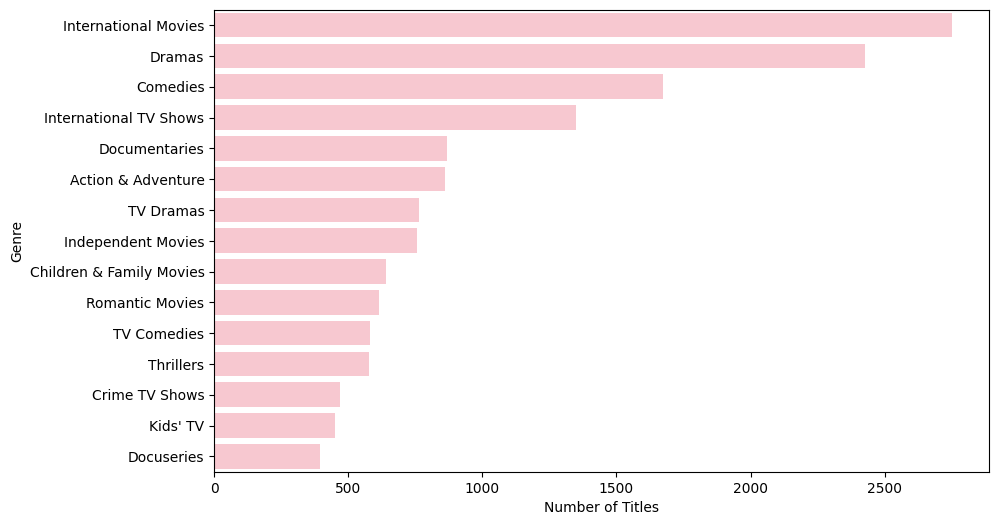

In [ ]:
genre_counts = (
    df["listed_in"]
    .str.split(", ")
    .explode()
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index,color="pink"
)
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.show()

** Movies vs TV Shows**



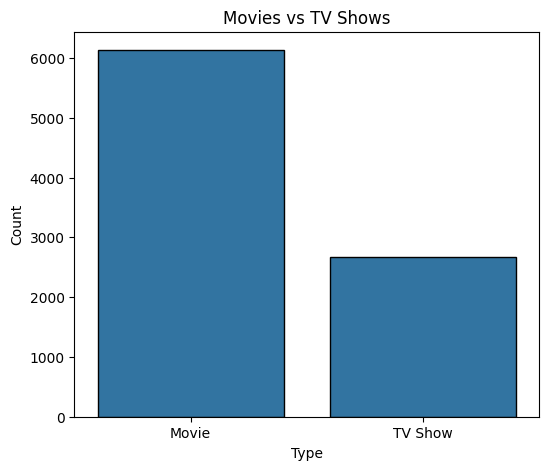

In [ ]:
plt.figure(figsize=(6,5))
sns.countplot(x="type", data=df,edgecolor="black")
plt.title("Movies vs TV Shows")
plt.xlabel("Type")
plt.ylabel("Count")
plt.show()

Data Visualization - Part 2:

Visualize the distribution of content across release years

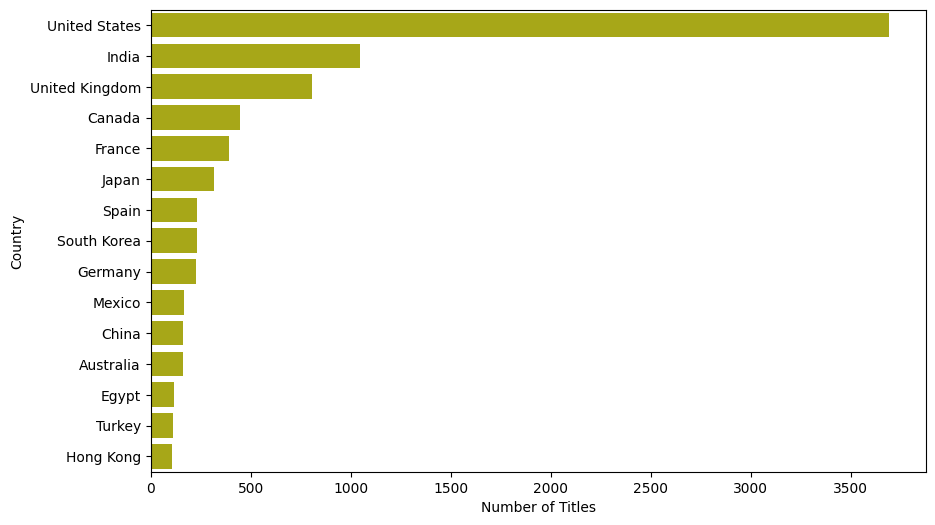

In [ ]:
country_counts = (
    df["country"]
    .str.split(", ")
    .explode()
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index,color="y"
)

plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

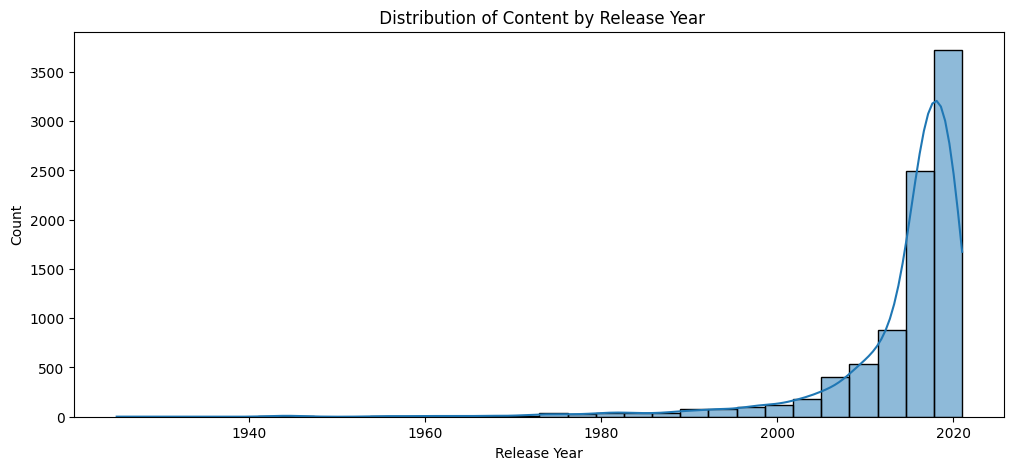

In [ ]:
plt.figure(figsize=(12,5))
sns.histplot(df["release_year"], bins=30, kde=True)
plt.title(" Distribution of Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Count")
plt.show()

Insight: The vast majority of titles were released in the last 10-15 years, with a sharp spike around 2017-2019. Very few titles release before 2000,

Data Visualization - Part 3:

Explore the geographical distribution of content (if applicable).


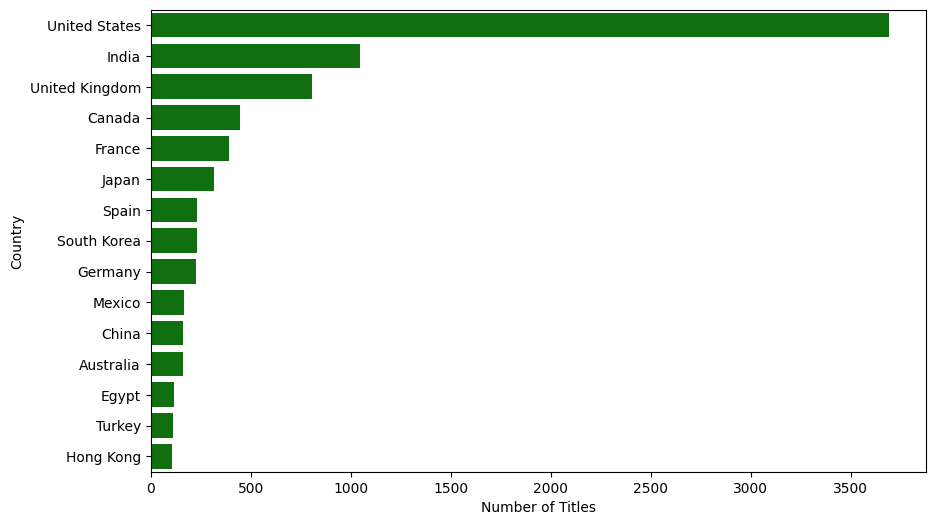

In [ ]:
country_counts = (
    df["country"]
    .str.split(", ")
    .explode()
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_counts.values,
    y=country_counts.index,color="g"
)

plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

Time Series Analysis:

If there's a temporal component, perform time series analysis to identify trends and patterns over
time.

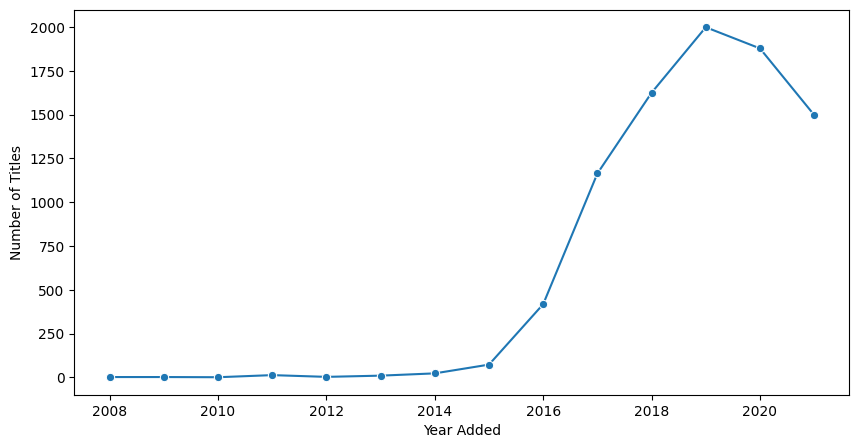

In [ ]:
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
df["year_added"] = df["date_added"].dt.year

titles_added_year = (
    df["year_added"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=titles_added_year.index,
    y=titles_added_year.values,
    marker="o"
)

plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.show()

Movies by Release Year

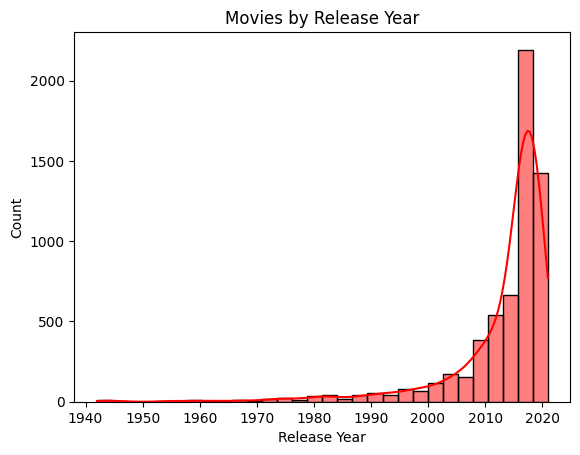

In [ ]:
movies = df[df["type"] == "Movie"]
sns.histplot(movies["release_year"], bins=30, kde=True,color="red")
plt.title("Movies by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Count")
plt.show()

Movies vs TV Shows by Release Year

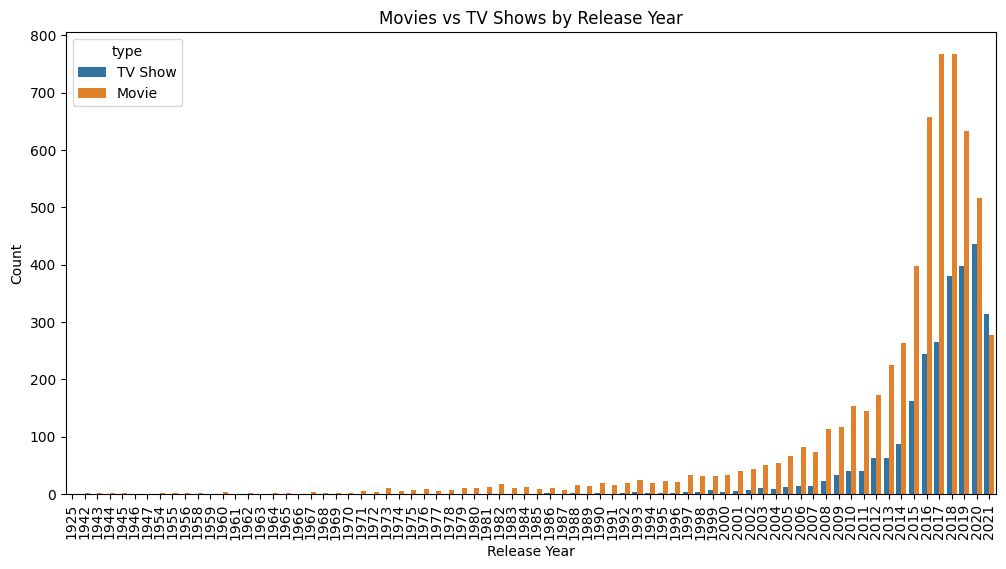

In [ ]:
plt.figure(figsize=(12,6))
sns.countplot(x="release_year", hue="type", data=df)
plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

TIME SERIES ANALYSIS - MONTHLY PATTERN

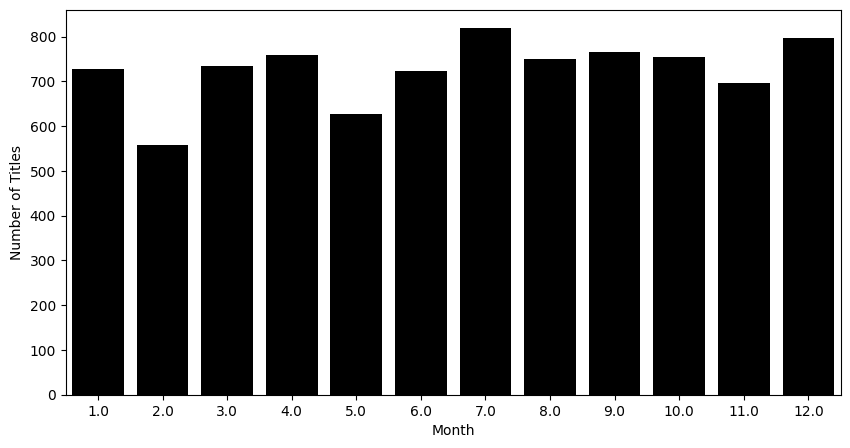

In [ ]:
df["month_added"] = df["date_added"].dt.month

monthly_additions = (
    df["month_added"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_additions.index,
    y=monthly_additions.values,color="black"
)

plt.xlabel("Month")
plt.ylabel("Number of Titles")
plt.show()

Content Analysis - Part 1:

Analyze the distribution of content ratings

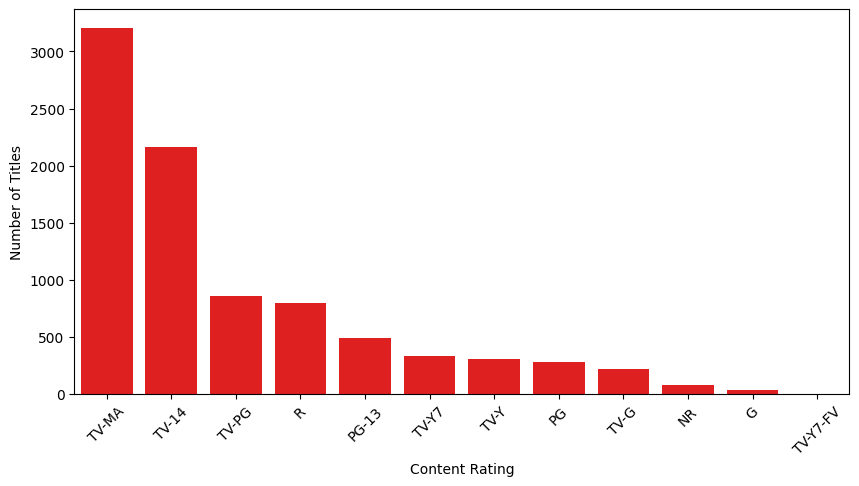

In [ ]:
rating_counts = (
    df["rating"]
    .value_counts()
    .head(12)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,color="red"
)

plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45)
plt.show()

Content Analysis - Part 2:

Explore the length of movies or episodes and identify any trends.

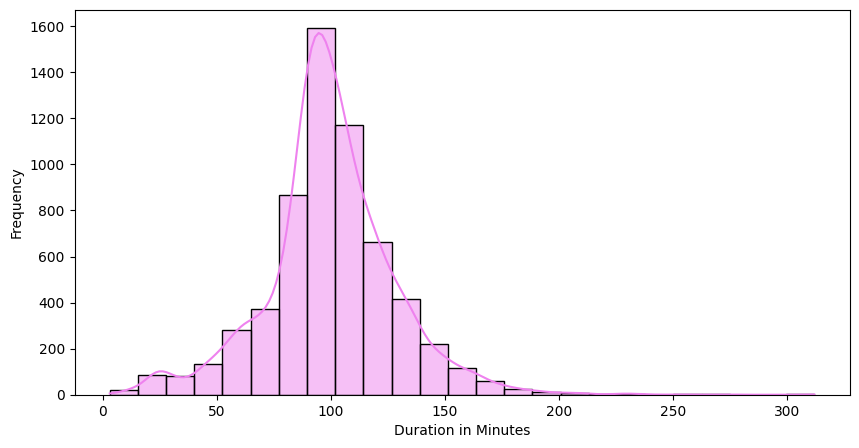

In [ ]:
movie_duration = pd.to_numeric(
    df.loc[
        df["type"] == "Movie",
        "duration"
    ]
    .str.extract(r"(\d+)")[0],
    errors="coerce"
)

plt.figure(figsize=(10, 5))

sns.histplot(
    movie_duration.dropna(),
    bins=25,
    kde=True,color="violet"
)

plt.xlabel("Duration in Minutes")
plt.ylabel("Frequency")
plt.show()

Distribution of Movie Duration (minutes)

In [ ]:
movies = df[df["type"] == "Movie"].copy()
movies["duration_min"] = movies["duration"].str.replace("min", "", regex=False).astype(float)
print("Average movie duration:", movies["duration_min"].mean())

Average movie duration: 99.57718668407311


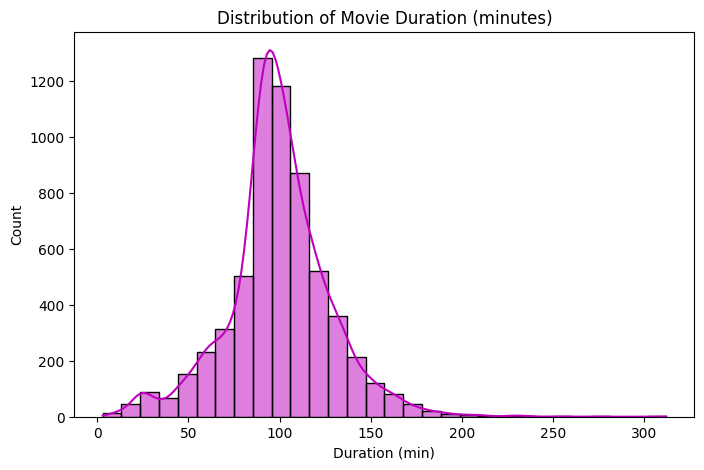

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(movies["duration_min"], bins=30, color="m", kde=True)
plt.title("Distribution of Movie Duration (minutes)")
plt.xlabel("Duration (min)")
plt.show()

Insight: Movie durations are roughly normally distributed, centered around 100 minutes

Top Lists and Recommendations:

Identify and present top-rated movies or TV shows based on user ratings

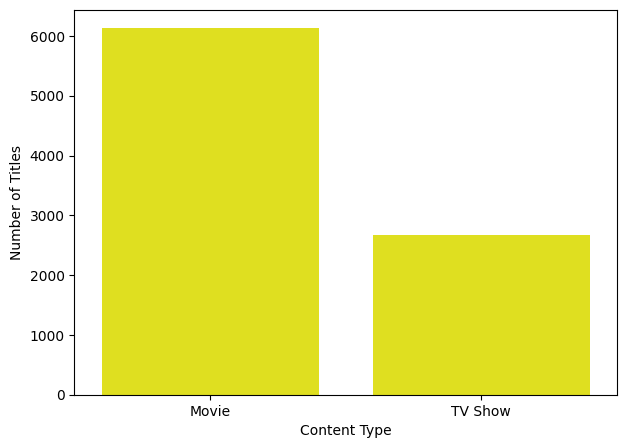

In [ ]:
type_counts = df["type"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=type_counts.index,
    y=type_counts.values,color="yellow"
)

plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.show()

Genre Trends:

Analyze trends in the popularity of different genres over time.

<Figure size 1200x600 with 0 Axes>

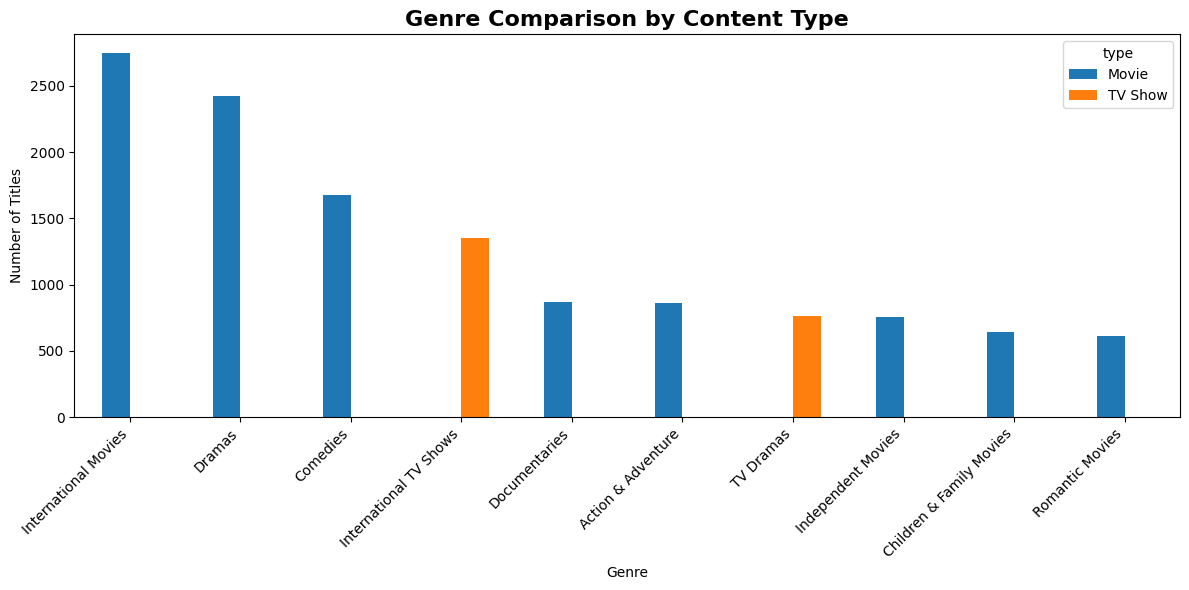

In [ ]:
genre_data = (
    df.assign(
        genre=df["listed_in"].str.split(", ")
    )
    .explode("genre")
)

top_genres = (
    genre_data["genre"]
    .value_counts()
    .head(10)
    .index
)

genre_type = pd.crosstab(
    genre_data["genre"],
    genre_data["type"]
).loc[top_genres]

plt.figure(figsize=(12, 6))
genre_type.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Genre")
plt.ylabel("Number of Titles")

plt.xticks(rotation=45, ha="right")

plt.title(
    "Genre Comparison by Content Type",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


Geographical Analysis:

Further explore the distribution of content across different countries and regions.


<Figure size 1200x600 with 0 Axes>

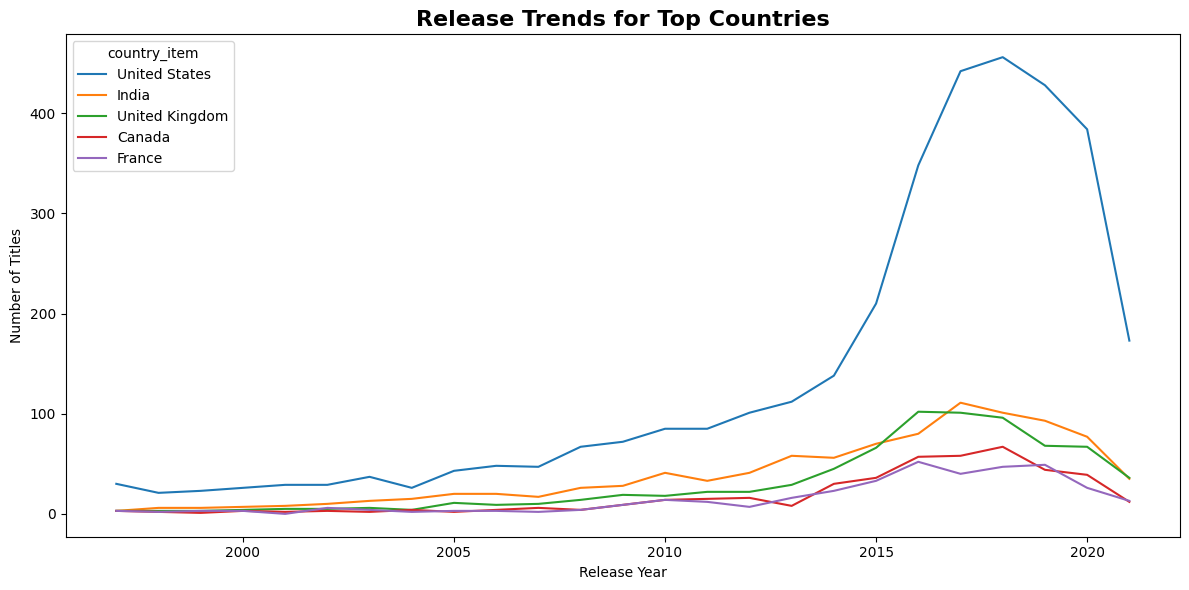

In [ ]:
country_data = (
    df.assign(
        country_item=df["country"].str.split(", ")
    )
    .explode("country_item")
)

top_countries = (
    country_data["country_item"]
    .value_counts()
    .head(5)
    .index
)

country_trend = pd.crosstab(
    country_data["release_year"],
    country_data["country_item"]
)[list(top_countries)]
country_trend = country_trend.tail(25)

plt.figure(figsize=(12, 6))

country_trend.plot(
    figsize=(12, 6)
)

plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.title(
    "Release Trends for Top Countries",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



Correlation Analysis:

Investigate potential correlations between variables (e.g., ratings and duration).


Correlation matrix:
                  release_year  duration_minutes
release_year          1.000000         -0.206285
duration_minutes     -0.206285          1.000000


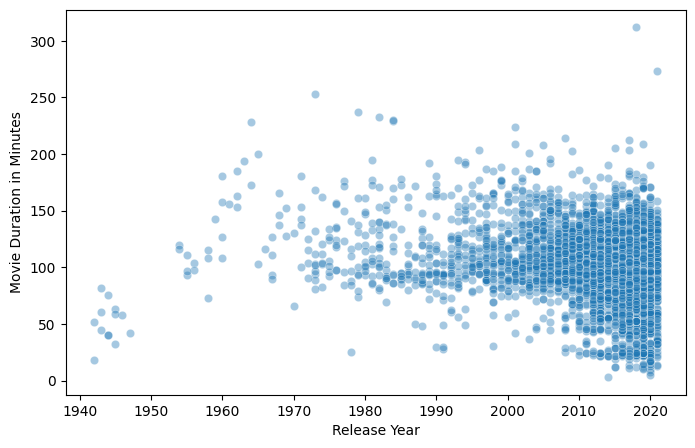

In [ ]:
movie_data = df[df["type"] == "Movie"].copy()

movie_data["duration_minutes"] = pd.to_numeric(
    movie_data["duration"]
    .str.extract(r"(\d+)")[0],
    errors="coerce"
)

correlation_data = movie_data[
    ["release_year", "duration_minutes"]
].dropna()

print("\nCorrelation matrix:")
print(correlation_data.corr())

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=correlation_data,
     x="release_year",
    y="duration_minutes",
    alpha=0.4
)

plt.xlabel("Release Year")
plt.ylabel("Movie Duration in Minutes")
plt.show()


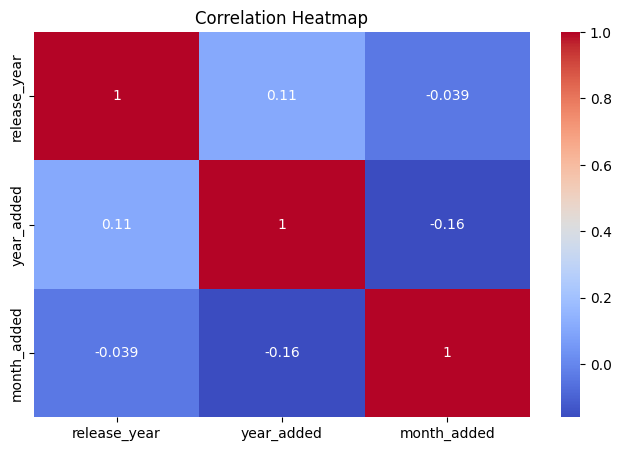

In [ ]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(8,5))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


# CORRELATION HEATMAP

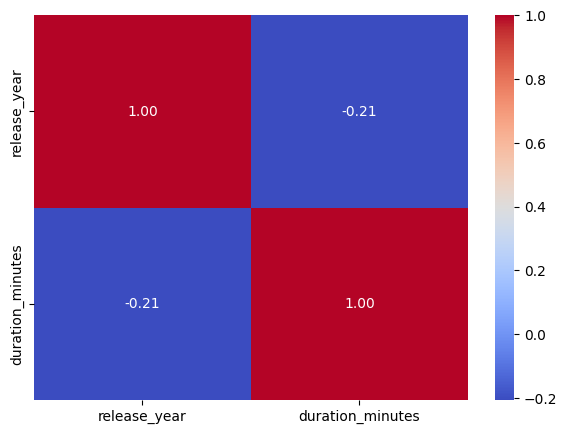

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.show()

Content Variety:

Evaluate the diversity of content by analyzing the number of unique genres and categories.


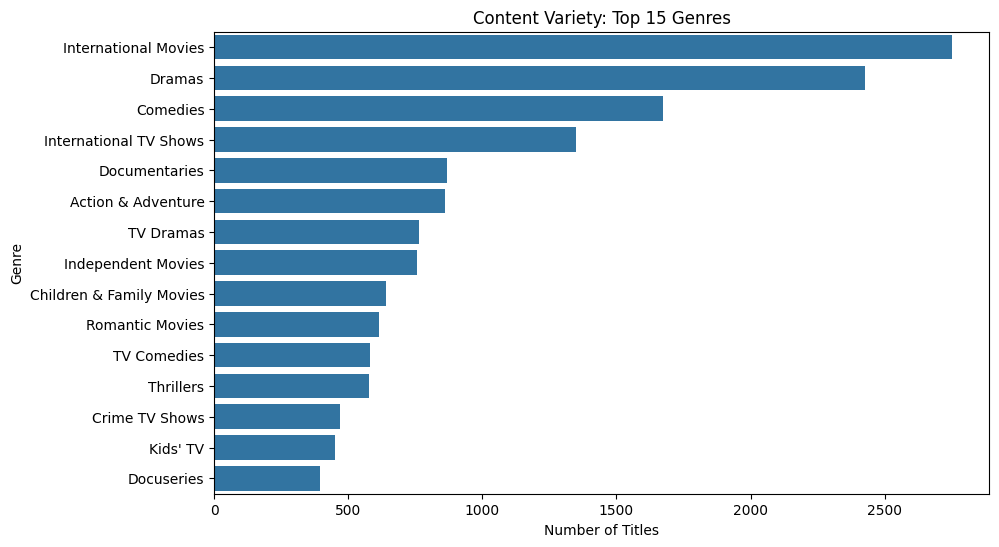

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=genre_counts.head(15).values,
    y=genre_counts.head(15).index
)

plt.title("Content Variety: Top 15 Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

plt.show()

User Preferences:


Investigate whether certain genres or types of content are more popular among users


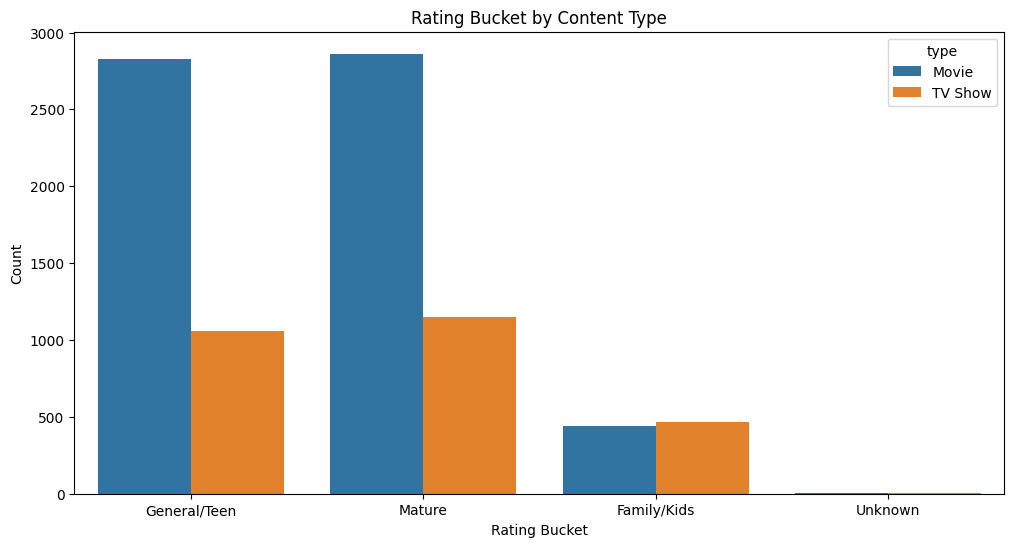

In [ ]:
mature = ["TV-MA","R","NC-17"]
family = ["TV-Y","TV-Y7","TV-G","G","TV-Y7-FV"]

def bucket(r):
    if r in mature: return "Mature"
    if r in family: return "Family/Kids"
    return "General/Teen"

df["rating_bucket"] = df["rating"].apply(lambda r: bucket(r) if pd.notna(r) else "Unknown")

plt.figure(figsize=(12,6))
sns.countplot(x="rating_bucket", hue="type", data=df)
plt.title("Rating Bucket by Content Type")
plt.xlabel("Rating Bucket")
plt.ylabel("Count")
plt.show()

Word Cloud of Genres

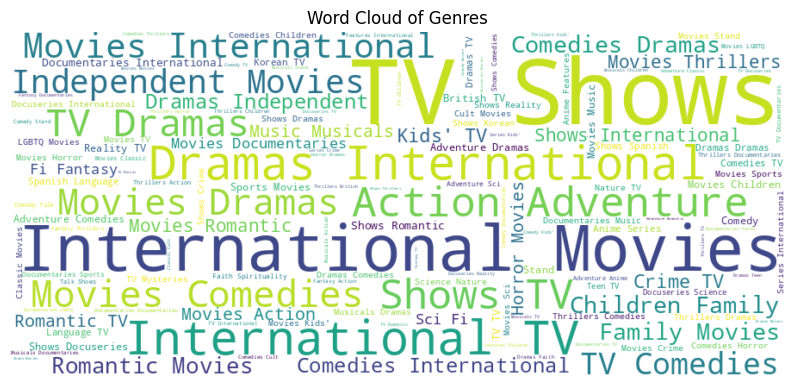

In [ ]:
from wordcloud import WordCloud

text = " ".join(df["listed_in"].astype(str))
wc = WordCloud(width=900, height=400, background_color="white").generate(text)

plt.figure(figsize=(10,5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Genres")
plt.show()

Conclusions and Recommendations:


Summarize the key findings, draw conclusions, and provide recommendations based on the insights gained from the analysis.


**      Data Cleaning**


      No duplicate values were found in the dataset.
      Original dataset size: 8,807 rows × 12 columns.
      director had 2,634 null values, which were filled with "Unknown".
      cast had 825 null values, which were filled with "Unknown".
      country had 831 null values, which were filled with "Unknown".
      rating had 4 null values, which were filled using the mode of the rating column.
      date_added had 10 null values and duration had 3 null values. Since these were very few, the corresponding rows were dropped.
      After cleaning, the dataset contains 8,794 rows × 12 columns.
      Therefore, only 13 rows were removed during data cleaning.


      **Statistical Insights**


      The mean release year is approximately 2014.
      The median release year is 2017.
      The mode release year is 2018, meaning 2018 had the highest number of releases.

     ** Genre Insights**


      Dramas are the most common primary genre.
      They are followed by Comedies and Action & Adventure.
      Documentaries and International TV Shows also have a strong presence.
      Despite having around 42 distinct genre tags, a small number of major genres account for a large portion of the catalog.

    **Release Year Insights**

      Most Netflix content was released within the last 10–15 years of the dataset.
      There is a sharp increase in content around 2017–2019.
      Very few titles were released before 2000.
      2018 had the highest number of content releases, followed by 2017 and 2019.
      Content additions declined after 2019.

      Top movie release years: 2018–2019.
      Top TV Show release years: 2019–2020.

      **Country Insights**

      The United States dominates as the primary production country.
      India is the second-largest contributor, followed by the United Kingdom.
      Approximately 54% of the catalog comes from the US and India combined, despite the dataset representing around 127 countries.

     ** Rating Insights**

      TV-MA is the most common rating.
      TV-14 is the second most common rating.
      This indicates a large proportion of Netflix content is targeted toward mature audiences and teenagers.

      **Movie vs TV Show**

      Movies are more numerous than TV Shows in the dataset.
      Movies were added to Netflix in greater numbers than TV Shows across most years.
      The number of TV Shows increased as a share of the catalog, particularly from around 2017 onward.

      **Duration Insights**

      Movie durations are approximately normally distributed, with most movies centered around 100 minutes.

      Family-rated content tends to have shorter durations, while teen/adult-rated content generally has longer durations.

      There is a weak negative correlation between release year and movie duration, meaning newer movies tend to be slightly shorter on average.

     ** TV Show Season Insights**
     
      The overwhelming majority of TV Shows on Netflix have only 1 season.
      This indicates that one-season TV Shows make up a significant portion of the Netflix TV catalog.

# ADDITIONAL VISUALIZATION
# Movies and TV Shows Over Time

<Figure size 1200x600 with 0 Axes>

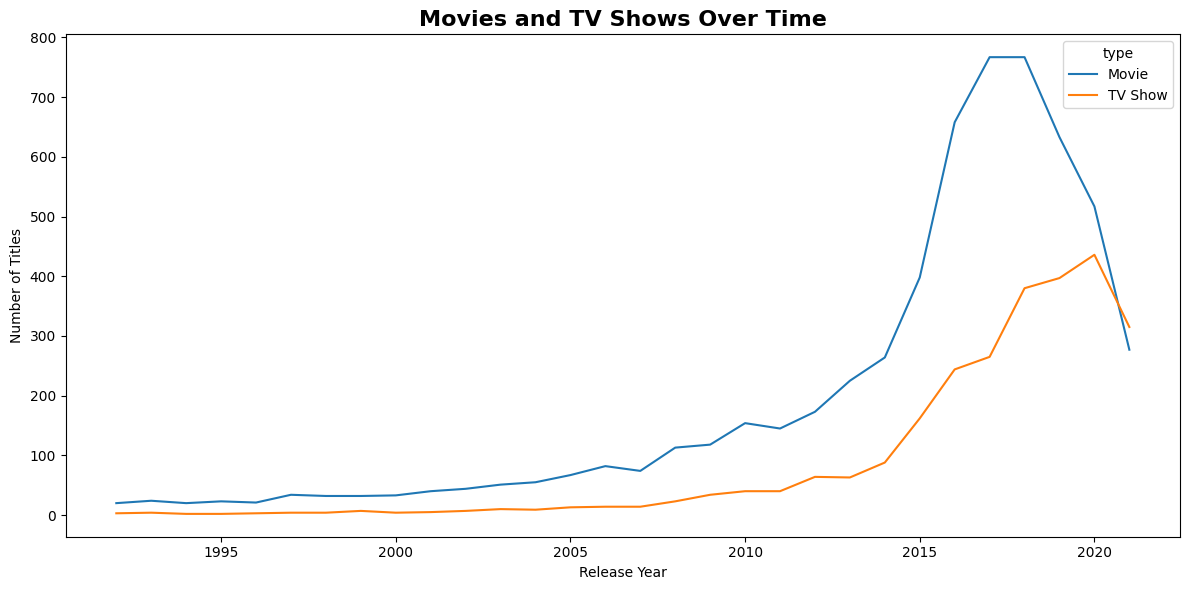

In [ ]:
type_over_time = pd.crosstab(
    df["release_year"],
    df["type"]
).tail(30)

plt.figure(figsize=(12, 6))

type_over_time.plot(
    figsize=(12, 6)
)

plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.title(
    "Movies and TV Shows Over Time",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# Top Directors

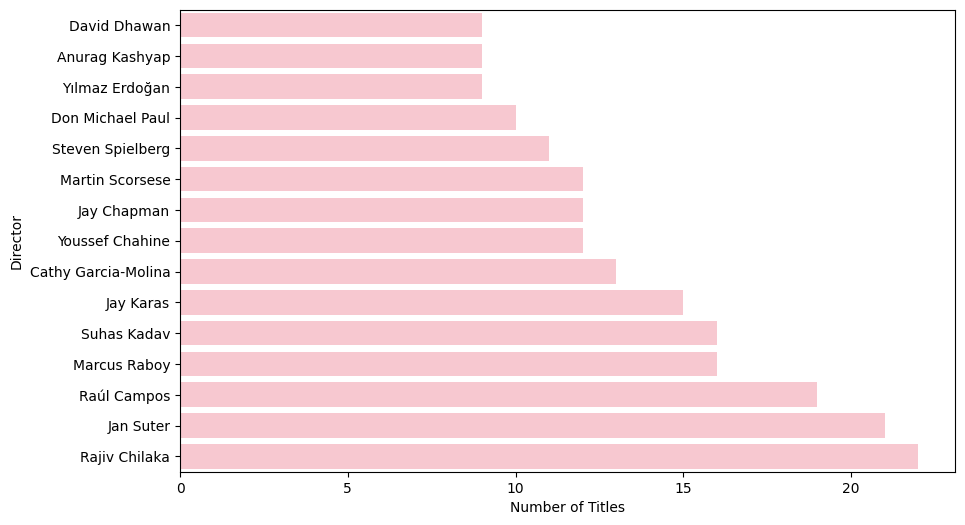

In [ ]:
director_counts = (
    df.loc[
        df["director"] != "Unknown",
        "director"
    ]
    .str.split(", ")
    .explode()
    .value_counts()
    .head(15)
    .sort_values()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=director_counts.values,
    y=director_counts.index,color="pink"
)

plt.xlabel("Number of Titles")
plt.ylabel("Director")
plt.show()




# Movie Duration Boxplot

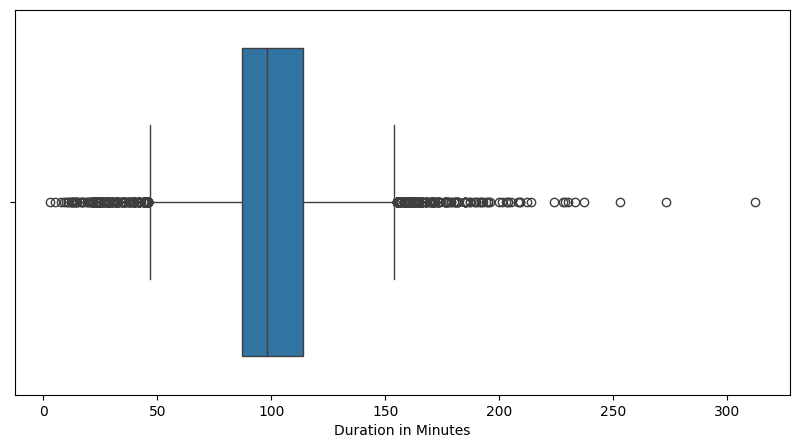

In [ ]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=movie_duration.dropna()
)

plt.xlabel("Duration in Minutes")

plt.show()


# TV Show Season Boxplot

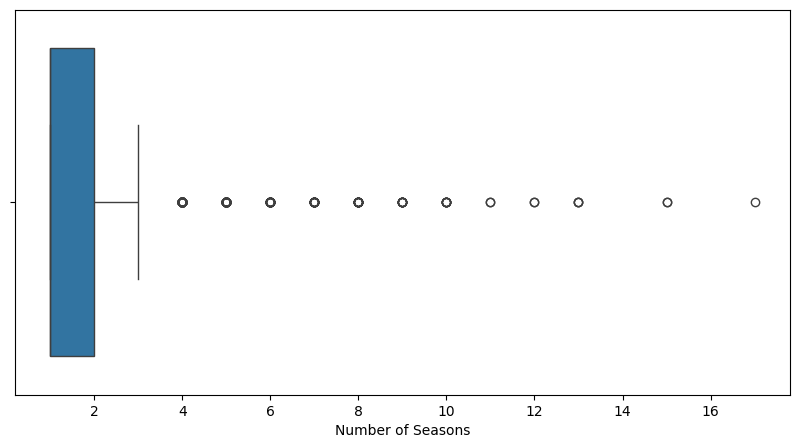

In [ ]:
tv_seasons = pd.to_numeric(
    df.loc[
        df["type"] == "TV Show",
        "duration"
    ]
    .str.extract(r"(\d+)")[0],
    errors="coerce"
)

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=tv_seasons.dropna()
)

plt.xlabel("Number of Seasons")
plt.show()

# Content Type Pie Chart

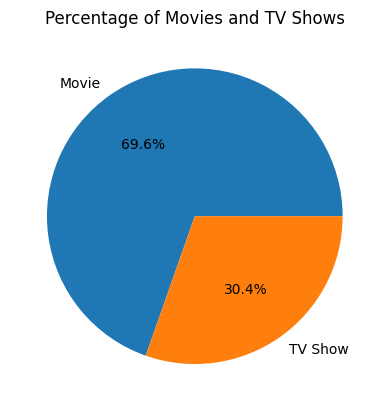

In [ ]:
df["type"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("Percentage of Movies and TV Shows")
plt.ylabel("")
plt.show()

# top 10 genres

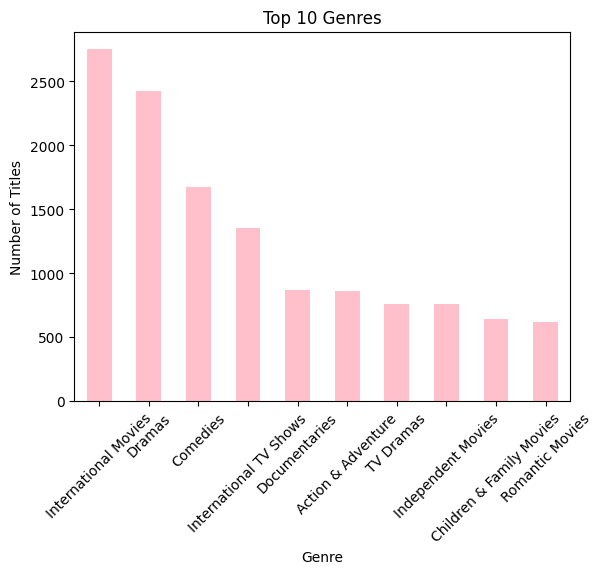

In [ ]:
genres = df["listed_in"].str.split(", ").explode()

genres.value_counts().head(10).plot(kind="bar", color="pink")

plt.title("Top 10 Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

#Content by Release Year

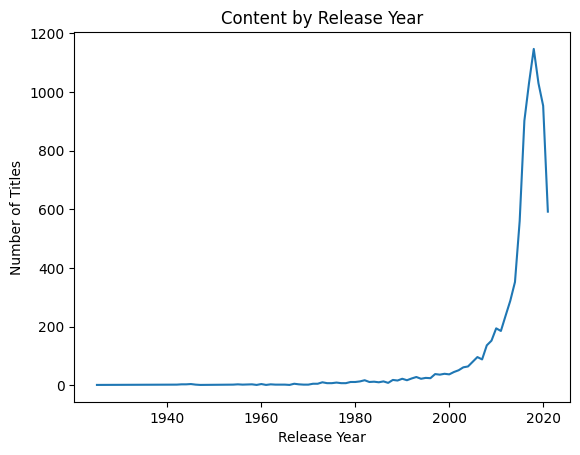

In [ ]:
df["release_year"].value_counts().sort_index().plot()

plt.title("Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()